https://github.com/iandriyash/ai-arhictect-2026-demo

# Домашнее задание: Кластеризация

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** разделить кредиты на группы по признакам, известным на момент выдачи, и посмотреть, отличаются ли группы по риску просрочки.

Используем K-Means и иерархическую кластеризацию. Признаки масштабируем, потому что алгоритмы считают расстояния.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Признаки

Берём признаки, известные на выдаче: доход, возраст, ставка, срок, сумма кредита, продукт.  
Целевую `is_overdue` в кластеризацию не кладём — она нужна только для интерпретации.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "is_overdue", "annual_income", "customer_age",
    "interest_rate", "term_months", "principal_amount", "loan_product_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)

feat_cols = [
    "annual_income", "customer_age", "interest_rate",
    "term_months", "principal_amount", "product_2",
]
X = work[feat_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Строк:", len(work))

Строк: 2477


## 2. K-Means: выбор числа кластеров

Метод локтя (WCSS) и силуэт для k от 2 до 7.

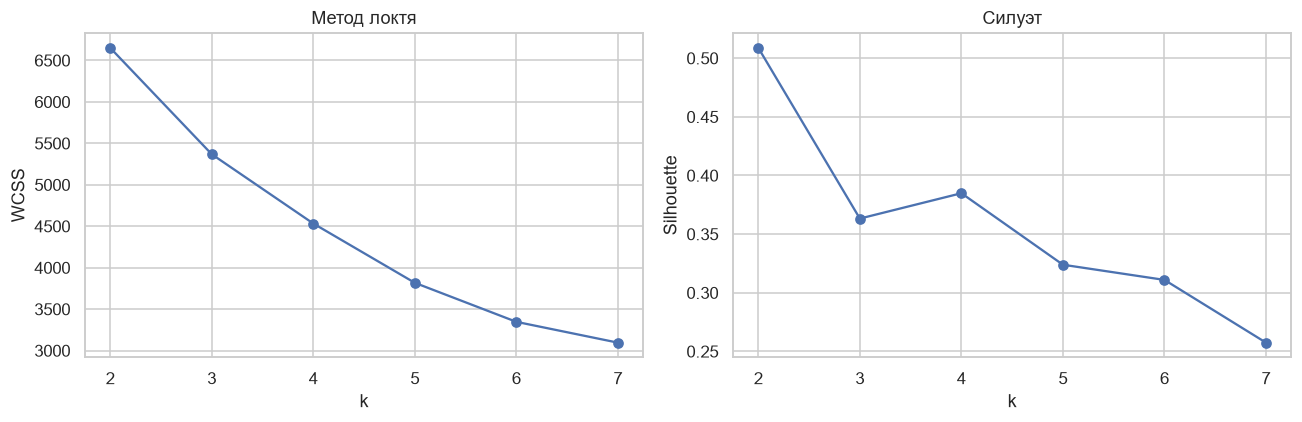

Лучший k по силуэту: 2
Silhouette по k: {2: 0.509, 3: 0.363, 4: 0.385, 5: 0.324, 6: 0.311, 7: 0.257}


In [3]:
ks = range(2, 8)
wcss = []
sil = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, wcss, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("WCSS")
axes[0].set_title("Метод локтя")

axes[1].plot(ks, sil, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Силуэт")
plt.tight_layout()
plt.show()

print("Лучший k по силуэту:", list(ks)[np.argmax(sil)])
print("Silhouette по k:", dict(zip(ks, [round(s, 3) for s in sil])))

**Выбор k.**  
Формально лучший k по силуэту — **2** (≈0.51), при 3 силуэт заметно падает, при 4 немного поднимается (≈0.39). Локоть выражен слабо: WCSS убывает плавно, чёткого излома нет, поэтому ориентируюсь на силуэт.  
k = 2 беру как основной вариант, но ниже проверяю, что он даёт: см. сравнение с продуктом. Дополнительно разберу k = 4 как второй локальный максимум силуэта.

In [4]:
k_best = 2
kmeans = KMeans(n_clusters=k_best, n_init=10, random_state=42)
work["kmeans"] = kmeans.fit_predict(X_scaled)
print(work["kmeans"].value_counts().sort_index())

kmeans
0    1503
1     974
Name: count, dtype: int64


## 3. Иерархическая кластеризация

Сравниваем linkage: Ward, average, complete. Число кластеров — то же, что у K-Means (2).

In [5]:
for link in ["ward", "average", "complete"]:
    agg = AgglomerativeClustering(n_clusters=2, linkage=link)
    work[f"hier_{link}"] = agg.fit_predict(X_scaled)
    print(link, work[f"hier_{link}"].value_counts().sort_index().to_dict())

ward {0: 1503, 1: 974}
average {0: 974, 1: 1503}
complete {0: 2111, 1: 366}


### Сравнение методов

Номера кластеров у разных методов не совпадают (у average они переставлены), поэтому сравниваю не по меткам, а через ARI (1.0 — разбиения одинаковы).

In [6]:
from sklearn.metrics import adjusted_rand_score

cmp_rows = [{"метод": "K-Means", "ARI с K-Means": 1.0,
             "silhouette": silhouette_score(X_scaled, work["kmeans"])}]
for link in ["ward", "average", "complete"]:
    lab = work[f"hier_{link}"]
    cmp_rows.append({"метод": f"Hier. {link}",
                     "ARI с K-Means": adjusted_rand_score(work["kmeans"], lab),
                     "silhouette": silhouette_score(X_scaled, lab)})
print(pd.DataFrame(cmp_rows).round(3).to_string(index=False))

print("\nK-Means (k=2) против продукта:")
print(pd.crosstab(work["kmeans"], work["product_2"]))

         метод  ARI с K-Means  silhouette
       K-Means           1.00        0.51
    Hier. ward           1.00        0.51
 Hier. average           1.00        0.51
Hier. complete          -0.01        0.19

K-Means (k=2) против продукта:
product_2     0    1
kmeans              
0          1503    0
1             0  974


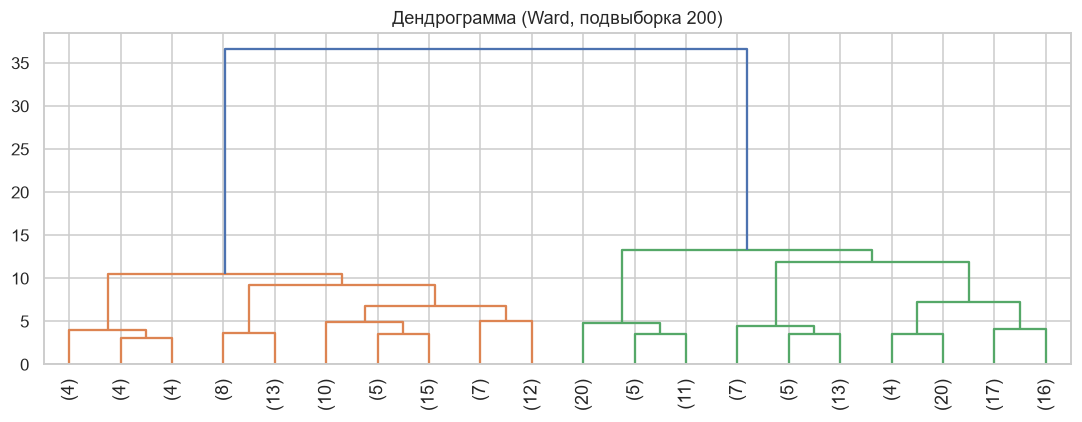

In [7]:
# Дендрограмма на подвыборке (полная на 2477 строках слишком тяжёлая)
sample = X_scaled[np.random.RandomState(42).choice(len(X_scaled), 200, replace=False)]
Z = linkage(sample, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90)
plt.title("Дендрограмма (Ward, подвыборка 200)")
plt.tight_layout()
plt.show()

## 4. Сравнение и профили кластеров

In [8]:
def profile(df, col):
    return df.groupby(col).agg(
        n=("is_overdue", "size"),
        overdue_rate=("is_overdue", "mean"),
        income=("annual_income", "median"),
        age=("customer_age", "median"),
        rate=("interest_rate", "median"),
        term=("term_months", "median"),
        amount=("principal_amount", "median"),
        product2=("product_2", "mean"),
    ).round(2)

print("=== K-Means ===")
print(profile(work, "kmeans"))
print("\n=== Hierarchical Ward ===")
print(profile(work, "hier_ward"))

=== K-Means ===
           n  overdue_rate       income   age  rate   term       amount  \
kmeans                                                                    
0       1503          0.21 1,879,788.24 44.00 20.42  36.00   662,231.20   
1        974          0.21 2,076,860.70 45.00 12.64 180.00 5,794,213.28   

        product2  
kmeans            
0           0.00  
1           1.00  

=== Hierarchical Ward ===
              n  overdue_rate       income   age  rate   term       amount  \
hier_ward                                                                    
0          1503          0.21 1,879,788.24 44.00 20.42  36.00   662,231.20   
1           974          0.21 2,076,860.70 45.00 12.64 180.00 5,794,213.28   

           product2  
hier_ward            
0              0.00  
1              1.00  


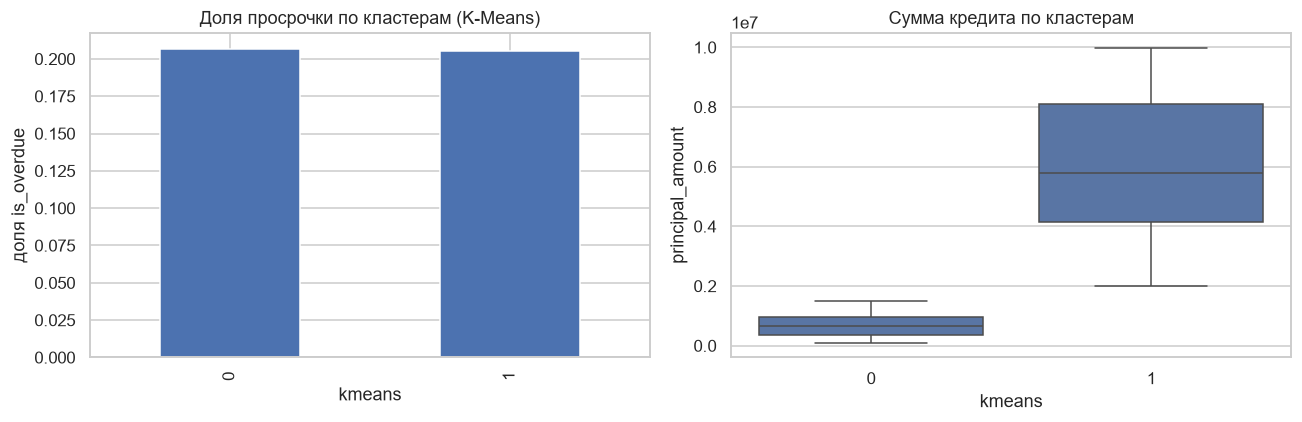

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

work.groupby("kmeans")["is_overdue"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Доля просрочки по кластерам (K-Means)")
axes[0].set_ylabel("доля is_overdue")

sns.boxplot(data=work, x="kmeans", y="principal_amount", ax=axes[1])
axes[1].set_title("Сумма кредита по кластерам")
plt.tight_layout()
plt.show()

## 4.1 Разбиение на 4 кластера

При k = 2 кластеры совпадают с продуктом и ничего не добавляют. Смотрю k = 4 (второй локальный максимум силуэта): продукт 2 остаётся отдельной группой, остальные кредиты делятся по возрасту и доходу. Целевая по-прежнему не участвует в кластеризации, только в интерпретации.

           n  overdue_rate       income   age  rate   term       amount  \
kmeans4                                                                   
0        574          0.21 1,813,294.14 55.00 20.39  36.00   701,086.32   
1        971          0.21 2,071,668.84 45.00 12.64 180.00 5,805,772.34   
2        245          0.13 4,584,218.52 49.00 20.36  36.00   855,098.20   
3        687          0.24 1,630,455.84 34.00 20.47  36.00   556,742.29   

         product2  
kmeans4            
0            0.00  
1            1.00  
2            0.01  
3            0.00  

Хи-квадрат, связь кластера с is_overdue: k=2 p=0.965, k=4 p=0.004


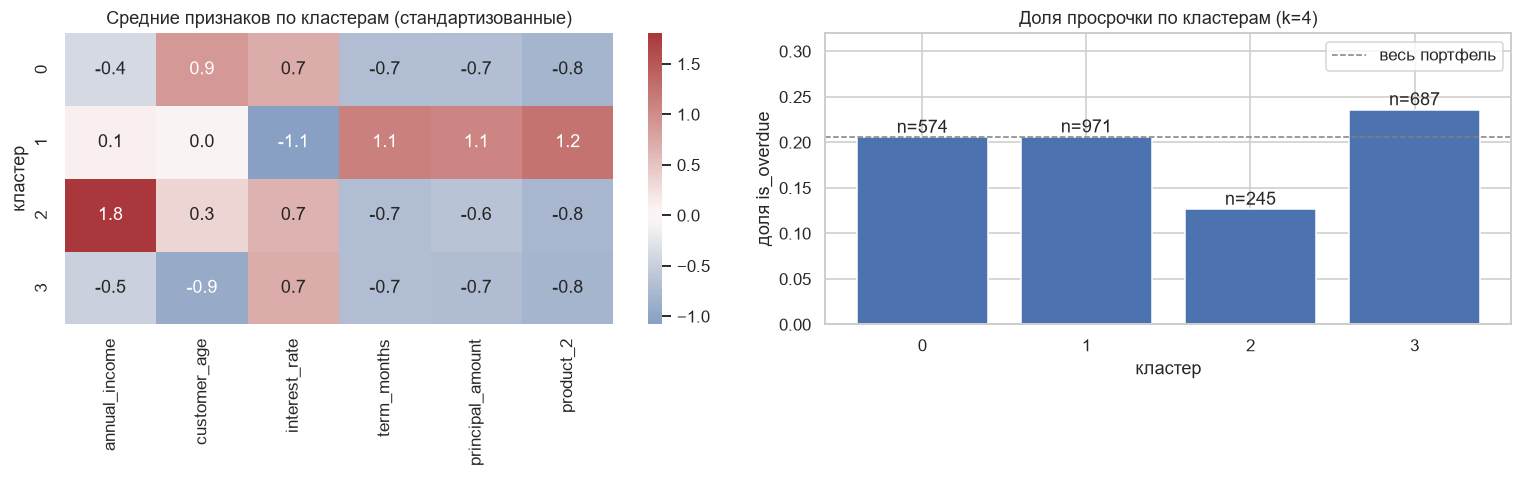

In [10]:
from scipy.stats import chi2_contingency

work["kmeans4"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_scaled)
print(profile(work, "kmeans4"))

p2 = chi2_contingency(pd.crosstab(work["kmeans"], work["is_overdue"]))[1]
p4 = chi2_contingency(pd.crosstab(work["kmeans4"], work["is_overdue"]))[1]
print(f"\nХи-квадрат, связь кластера с is_overdue: k=2 p={p2:.3f}, k=4 p={p4:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

means = pd.DataFrame(X_scaled, columns=feat_cols).groupby(work["kmeans4"].values).mean()
sns.heatmap(means, annot=True, fmt=".1f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Средние признаков по кластерам (стандартизованные)")
axes[0].set_xlabel("")
axes[0].set_ylabel("кластер")

rate = work.groupby("kmeans4")["is_overdue"].agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color="#4C72B0")
axes[1].axhline(work["is_overdue"].mean(), color="gray", ls="--", lw=1, label="весь портфель")
for pos, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(pos, m + 0.005, f"n={n}", ha="center")
axes[1].set_xlabel("кластер")
axes[1].set_ylabel("доля is_overdue")
axes[1].set_title("Доля просрочки по кластерам (k=4)")
axes[1].set_ylim(0, 0.32)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [11]:
# Иерархическая кластеризация с теми же 4 кластерами: здесь правила группировки различаются
from sklearn.metrics import adjusted_rand_score

rows4 = []
for link in ["ward", "average", "complete", "single"]:
    lab = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X_scaled)
    rows4.append({
        "linkage": link,
        "размеры кластеров": sorted(np.bincount(lab), reverse=True),
        "ARI с K-Means (k=4)": adjusted_rand_score(work["kmeans4"], lab),
        "silhouette": silhouette_score(X_scaled, lab),
    })
print(pd.DataFrame(rows4).round(3).to_string(index=False))

 linkage     размеры кластеров  ARI с K-Means (k=4)  silhouette
    ward  [974, 845, 463, 195]                 0.83        0.37
 average   [1503, 809, 161, 4]                 0.45        0.40
complete [1250, 861, 253, 113]                 0.64        0.33
  single     [1502, 971, 3, 1]                 0.55        0.41


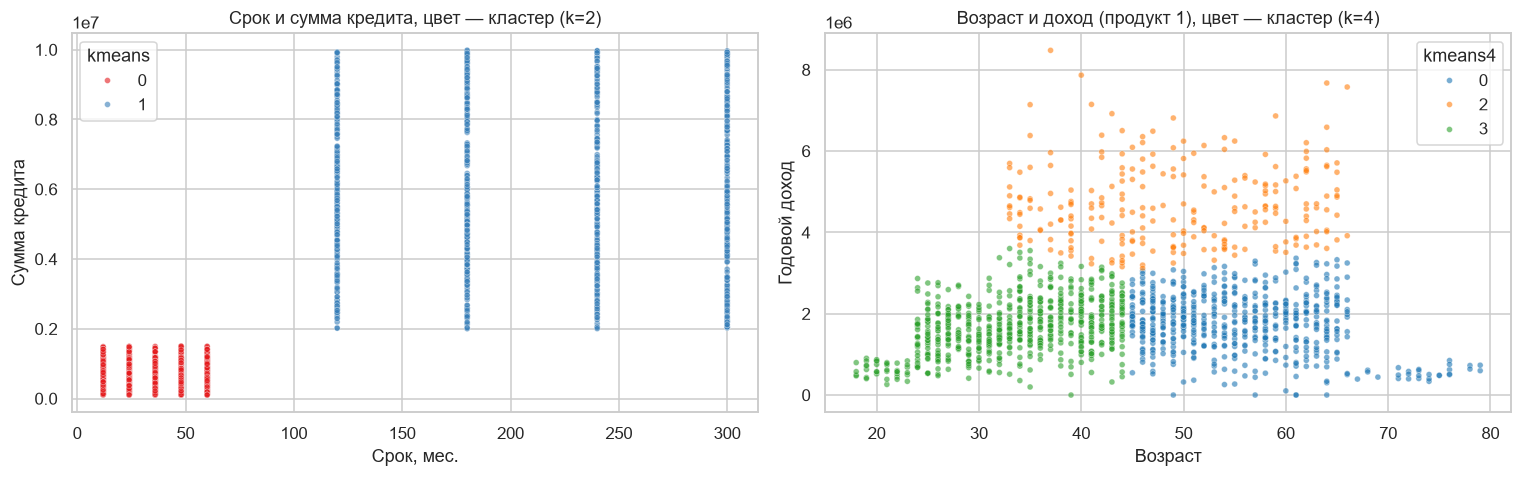

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=work, x="term_months", y="principal_amount", hue="kmeans",
                palette="Set1", s=15, alpha=0.6, ax=axes[0])
axes[0].set_title("Срок и сумма кредита, цвет — кластер (k=2)")
axes[0].set_xlabel("Срок, мес.")
axes[0].set_ylabel("Сумма кредита")

sns.scatterplot(data=work[work["product_2"] == 0], x="customer_age", y="annual_income", hue="kmeans4",
                palette="tab10", s=15, alpha=0.6, ax=axes[1])
axes[1].set_title("Возраст и доход (продукт 1), цвет — кластер (k=4)")
axes[1].set_xlabel("Возраст")
axes[1].set_ylabel("Годовой доход")

plt.tight_layout()
plt.show()

## 5. Выводы

**Кластеры K-Means (k=2).**  
Две группы полностью совпадают с продуктом. Продукт 2: крупные суммы (медиана ≈5.8 млн), срок ≈180 мес., ставка ≈12.6%. Остальные: суммы ≈0.7 млн, срок 36 мес., ставка ≈20%. Доход и возраст различаются слабо. Высокий силуэт (≈0.51) получился потому, что продукт однозначно задаёт сумму, срок и ставку, а не потому, что в данных есть богатая структура.

**Иерархическая кластеризация.**  
При двух кластерах Ward, average и complete дают то же разбиение, что K-Means (ARI в таблице сравнения): продукт делит данные слишком чётко. При четырёх кластерах правила группировки уже различаются: Ward близок к K-Means (ARI ≈ 0.83), average и complete дают менее похожие разбиения, а single почти ничего не делит: остаются два больших кластера по продукту и два кластера из 1–3 кредитов (эффект «цепочки»; высокий силуэт у single обманчив). Для интерпретации подходят K-Means и Ward.

**Разбиение на 4 кластера.**  
Продукт 2 остаётся одной группой, а остальные кредиты делятся по возрасту и доходу: самые молодые заёмщики (медиана 34 года, доход ≈1.6 млн), более старшие (медиана 55 лет) и небольшая группа с очень высоким доходом (медиана ≈4.6 млн).

**Связь с просрочкой.**  
При k=2 доля `is_overdue` в обеих группах одинакова (≈21%, p ≈ 0.96), то есть кластеры по продукту риск не разделяют. При k=4 доля просрочки различается от ≈13% до ≈24% (p ≈ 0.004): ниже всех у группы с очень высоким доходом, выше всех у самых молодых. Это согласуется с ПА-1: в хвосте дохода риск ниже. Различия умеренные, кластеры описывают группы внутри этой выборки и не являются прогнозом.

**Бизнес-смысл.**  
k=2 — это сегменты по типу продукта. k=4 добавляет портрет заёмщика и может служить сегментами для разных правил проверки и мониторинга. Как прямой предиктор просрочки кластеры использовать нельзя: целевая в них не участвовала.